# AI-generated text detection

This notebook implements our project on the detection of human-written and AI-generated English answers.
We compared a majority baseline, TF-IDF logistic regression, and fine-tuned DistilBERT on the HC3 dataset.
We used macro-average F1 as our main metric. We also measured errors that label human text as AI-generated.

**Research question:** Does fine-tuned DistilBERT improve macro-average F1 over TF-IDF logistic regression on the chosen dataset?


**How to run:** We select the course NLP environment as the kernel and use **Restart Kernel and Run All**.
All settings are in Section 1. If the total runtime at the end is over one hour, we reduce `number_of_questions`
or increase `frozen_transformer_layers`, then run all cells again.

## 1. Imports and settings

In [1]:
# We install pandas if it is missing, because the NLP VM does not include it by default.
try:
    import pandas as pd
except ImportError:
    %pip install -q pandas
    import pandas as pd


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import necessary libraries
import time

import copy
import json
import os
import random
import unicodedata
from datetime import datetime
from pathlib import Path

# We turn off tokenizer parallelism to avoid warnings in the notebook.
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download, snapshot_download
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_fscore_support,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from torch.utils.data import DataLoader, Dataset
from transformers import AutoModelForSequenceClassification, AutoTokenizer

In [3]:
class_names = ["human-written", "AI-generated"]

# Plot settings: a light grid, no top and right borders, and one fixed color for each model.
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})
class_colors = ["#2a78d6", "#eb6834"]
model_colors = {
    "Majority baseline": "#898781",
    "TF-IDF logistic regression": "#2a78d6",
    "DistilBERT": "#eb6834",
}
training_color = "#2a78d6"
validation_color = "#eb6834"

In [4]:
# Experiment settings
SEED = 42
number_of_questions = 2500
maximum_input_tokens = 128
batch_size = 16
number_of_epochs = 5
learning_rate = 0.00002
weight_decay = 0.01
frozen_transformer_layers = 0
maximum_tfidf_features = 20_000
decision_threshold = 0.5

# Runtime settings for the one-hour limit
runtime_limit_seconds = 3600
maximum_cpu_threads = 4

In [5]:
# We create a new output folder for each run.
project_directory = Path.cwd()
if not (project_directory / "AI_Text_Detection.ipynb").exists():
    raise FileNotFoundError("Open this notebook from the ai_text_detection folder.")

run_identifier = datetime.now().strftime("%Y%m%d_%H%M%S")
output_directory = project_directory / "outputs" / run_identifier
output_directory.mkdir(parents=True, exist_ok=False)

# We use a GPU if one is available. The NLP VM has only a CPU.
computing_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cpu_thread_count = min(maximum_cpu_threads, os.cpu_count())
torch.set_num_threads(cpu_thread_count)

# We check that the settings are in a sensible range.
assert number_of_questions >= 20
assert 1 <= number_of_epochs <= 5
assert 0 <= frozen_transformer_layers <= 5
assert 4 <= maximum_input_tokens <= 512

# We print the main details of this run.
print("PyTorch version:", torch.__version__)
print("Device:", computing_device)
print("CPU threads:", cpu_thread_count)
print("Run outputs:", output_directory)

PyTorch version: 2.13.0+cu130
Device: cpu
CPU threads: 4
Run outputs: /home/fcsvmuser/Downloads/outputs/20261121_150944


In [6]:
def set_random_seeds(random_seed):
    # We fix the random seeds so repeated runs give the same results.
    random.seed(random_seed)
    np.random.seed(random_seed)
    torch.manual_seed(random_seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(random_seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def save_json(file_path, content):
    file_path.write_text(json.dumps(content, indent=2), encoding="utf-8")

def calculate_metrics(true_labels, predicted_labels):
    # Label 0 is human-written and label 1 is AI-generated.
    precision, recall, class_f1, support = precision_recall_fscore_support(
        true_labels, predicted_labels, labels=[0, 1], zero_division=0
    )
    confusion_counts = confusion_matrix(true_labels, predicted_labels, labels=[0, 1])
    human_text_count = int(confusion_counts[0].sum())
    return {
        "macro_f1": float(f1_score(true_labels, predicted_labels, labels=[0, 1], average="macro", zero_division=0)),
        "accuracy": float(accuracy_score(true_labels, predicted_labels)),
        "human_precision": float(precision[0]),
        "human_recall": float(recall[0]),
        "human_f1": float(class_f1[0]),
        "ai_generated_precision": float(precision[1]),
        "ai_generated_recall": float(recall[1]),
        "ai_generated_f1": float(class_f1[1]),
        "human_false_positive_rate": float(confusion_counts[0, 1] / human_text_count) if human_text_count else None,
        "human_support": int(support[0]),
        "ai_generated_support": int(support[1]),
    }

set_random_seeds(SEED)
# We save the settings of this run for the report.
save_json(output_directory / "configuration.json", {
    "number_of_questions": number_of_questions,
    "maximum_input_tokens": maximum_input_tokens,
    "batch_size": batch_size,
    "number_of_epochs": number_of_epochs,
    "learning_rate": learning_rate,
    "weight_decay": weight_decay,
    "frozen_transformer_layers": frozen_transformer_layers,
    "maximum_tfidf_features": maximum_tfidf_features,
    "runtime_limit_seconds": runtime_limit_seconds,
    "maximum_cpu_threads": maximum_cpu_threads,
})

## 2. Data and model files

We used the public English HC3 file, `all.jsonl`, from [Hello-SimpleAI/HC3](https://huggingface.co/datasets/Hello-SimpleAI/HC3).
Each record contains a question, human answers, ChatGPT answers, and a source.
We start the runtime timer after this download, and we record the download time separately.

In [7]:
# Set the variables for the dataset and model download
dataset_repository = "Hello-SimpleAI/HC3"
model_repository = "distilbert/distilbert-base-uncased"

# We set this to True after the first download to run without internet.
local_files_only = False

download_start_time = time.perf_counter()

# Download the dataset from Hugging Face Hub
dataset_path = Path(hf_hub_download(
    repo_id=dataset_repository,
    filename="all.jsonl",
    repo_type="dataset",
    local_files_only=local_files_only,
    token=False,
))

# Download the pretrained DistilBERT model from Hugging Face Hub
pretrained_distilbert_model_directory = snapshot_download(
    repo_id=model_repository,
    allow_patterns=["config.json", "model.safetensors", "tokenizer.json", "tokenizer_config.json", "vocab.txt"],
    local_files_only=local_files_only,
    token=False,
)

# Load the tokenizer for the pretrained DistilBERT model
tokenizer = AutoTokenizer.from_pretrained(pretrained_distilbert_model_directory, use_fast=True, local_files_only=True)

# Make sure the tokenizer is a fast tokenizer
assert tokenizer.is_fast
# Calculate the time taken for downloading the dataset and model
download_seconds = time.perf_counter() - download_start_time

# We start the runtime timer after the download, so network speed does not count toward the one-hour limit.
run_start_time = time.perf_counter()

# Each line of the dataset file is one JSON record.
with dataset_path.open(encoding="utf-8") as dataset_file:
    dataset_records = [json.loads(line) for line in dataset_file if line.strip()]

print("Raw question records:", len(dataset_records))

all.jsonl: reconstructing file:   0%|          |  0.00B / 73.7MB            

all.jsonl: downloading bytes:           |  0.00B            

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Raw question records: 24322


## 3. Prepare paired answers

We applied Unicode and whitespace normalization to both classes. We kept punctuation and stop words.
We grouped questions by normalized, case-insensitive text and kept the first record for each question.
We used a fixed seed to choose one nonempty answer from each class for each eligible question.

We used the tokenizer offsets to keep the start of each answer within 126 content tokens.
DistilBERT adds two special tokens, which gives at most 128 input tokens.
Both learned models receive the same passage text, but their tokenization methods still differ.

We removed a whole question pair if either selected answer repeated an earlier answer or tokenized passage.
We also removed pairs with identical passages across the two labels. We did this before sampling and splitting.
This conservative check removes exact duplicates; it does not detect all paraphrases or related questions.

In [8]:
def normalize_text(text:str) -> str:
    # We apply Unicode normalization and replace repeated whitespace with one space.
    return " ".join(unicodedata.normalize("NFKC", text).split())

def choose_answer_pairs(records:list, random_seed:int) -> tuple:
    # We keep the first record of each question and choose one answer from each class.
    answer_generator = random.Random(random_seed)
    seen_questions = set()
    answer_pairs = []
    duplicate_questions = 0
    skipped_records = 0

    for record_index, record in enumerate(records):
        question_text = normalize_text(record["question"]).casefold()
        if not question_text:
            skipped_records += 1
            continue
        if question_text in seen_questions:
            duplicate_questions += 1
            continue
        seen_questions.add(question_text)
        human_answers = [normalize_text(answer) for answer in record["human_answers"] if normalize_text(answer)]
        ai_generated_answers = [normalize_text(answer) for answer in record["chatgpt_answers"] if normalize_text(answer)]
        if not human_answers or not ai_generated_answers:
            skipped_records += 1
            continue
        answer_pairs.append({
            "question_id": record_index,
            "source": record["source"],
            "answers": [answer_generator.choice(human_answers), answer_generator.choice(ai_generated_answers)],
        })
    return answer_pairs, duplicate_questions, skipped_records


def cut_passages_and_remove_duplicates(answer_pairs:list, text_tokenizer:AutoTokenizer, maximum_input_tokens:int) -> tuple:
    # DistilBERT adds two special tokens, so we keep two fewer content tokens than the input limit.
    content_token_limit = maximum_input_tokens - text_tokenizer.num_special_tokens_to_add(pair=False)
    answer_texts = [answer for answer_pair in answer_pairs for answer in answer_pair["answers"]]
    tokenized_answers = text_tokenizer(
        answer_texts, add_special_tokens=False, truncation=True,
        max_length=content_token_limit, return_offsets_mapping=True,
    )
    prepared_rows = []
    seen_answer_texts = set()
    seen_token_sequences = set()
    removed_pairs = 0

    for pair_index, answer_pair in enumerate(answer_pairs):
        pair_rows = []
        pair_answer_texts = []
        pair_token_sequences = []
        for label, answer_text in enumerate(answer_pair["answers"]):
            answer_index = 2 * pair_index + label
            token_ids = tuple(tokenized_answers["input_ids"][answer_index])
            offsets = tokenized_answers["offset_mapping"][answer_index]
            # The end of the last kept token shows where to cut the original text.
            passage_text = answer_text[:offsets[-1][1]] if offsets else ""
            pair_answer_texts.append(answer_text.casefold())
            pair_token_sequences.append(token_ids)
            pair_rows.append({
                "question_id": answer_pair["question_id"],
                "source": answer_pair["source"],
                "label": label,
                "passage_text": passage_text,
                "content_token_count": len(token_ids),
                "original_word_count": len(answer_text.split()),
                "was_truncated": len(passage_text) < len(answer_text),
            })

        # We drop the whole pair if a passage is empty, both answers are the same, or an answer appeared before.
        has_empty_passage = any(not row["passage_text"] for row in pair_rows)
        has_identical_answers = len(set(pair_answer_texts)) < 2 or len(set(pair_token_sequences)) < 2
        has_repeated_answer = (
            any(answer in seen_answer_texts for answer in pair_answer_texts)
            or any(tokens in seen_token_sequences for tokens in pair_token_sequences)
        )
        if has_empty_passage or has_identical_answers or has_repeated_answer:
            removed_pairs += 1
            continue
        prepared_rows.extend(pair_rows)
        seen_answer_texts.update(pair_answer_texts)
        seen_token_sequences.update(pair_token_sequences)

    return pd.DataFrame(prepared_rows), removed_pairs


answer_pairs, duplicate_questions, skipped_records = choose_answer_pairs(dataset_records, SEED)
prepared_answers, removed_pairs = cut_passages_and_remove_duplicates(answer_pairs, tokenizer, maximum_input_tokens)
preparation_counts = {
    "raw_records": len(dataset_records),
    "duplicate_question_records": duplicate_questions,
    "empty_or_incomplete_records": skipped_records,
    "duplicate_or_empty_passage_pairs": removed_pairs,
    "eligible_question_pairs": len(prepared_answers) // 2,
}
save_json(output_directory / "preparation_counts.json", preparation_counts)
display(pd.Series(preparation_counts, name="Count").to_frame())

,Count
raw_records,24322
duplicate_question_records,833
empty_or_incomplete_records,452
duplicate_or_empty_passage_pairs,486
eligible_question_pairs,22551


## 4. Sample and split by question

We sampled 2,500 eligible questions without replacement. Each question contributes one answer from each class.
We used an 80/10/10 split by question, so paired answers cannot enter different sets.
We checked that no question or passage appears in more than one set.
We saved the split membership so we can reconstruct the experiment.

We inspected source and class counts for all sets. We used training text only for the exploratory length summary.
We did not use test predictions to select a model.
We also plotted the answer lengths of both classes in the training set.

human-written  AI-generated
split      source                                  
test       finance                 41            41
           medicine                14            14
           open_qa                 10            10
           reddit_eli5            179           179
           wiki_csai                6             6
training   finance                354           354
           medicine               101           101
           open_qa                 92            92
           reddit_eli5           1381          1381
           wiki_csai               72            72
validation finance                 41            41
           medicine                17            17
           open_qa                 21            21
           reddit_eli5            164           164
           wiki_csai                7             7

,original_word_count,content_token_count,was_truncated
label,,,
human-written,134.0585,86.1910,0.3920
AI-generated,178.3485,122.9285,0.8895


Overlap checks passed. Answers per split: {'training': 4000, 'validation': 500, 'test': 500}


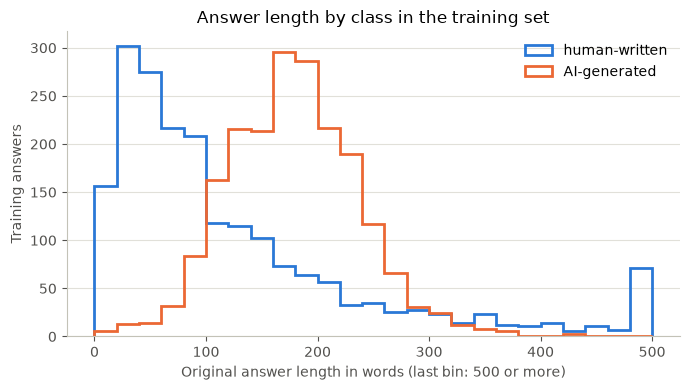

In [9]:
def split_question_pairs(answer_table:pd.DataFrame, number_of_questions:int, random_seed:int) -> dict:
    """
    This function splits the answer pairs into training, validation, and test sets based on the number of questions specified.
    It ensures that both answers to a question stay in the same set and that no question or passage appears in two different sets.
    """
    
    question_table = answer_table[["question_id", "source"]].drop_duplicates("question_id")
    if number_of_questions > len(question_table):
        raise ValueError("The requested sample exceeds the number of eligible question pairs.")
    selected_questions = question_table.sample(n=number_of_questions, random_state=random_seed)
    training_questions, held_out_questions = train_test_split(
        selected_questions["question_id"], test_size=0.2, random_state=random_seed
    )
    validation_questions, test_questions = train_test_split(
        held_out_questions, test_size=0.5, random_state=random_seed
    )
    question_splits = {
        "training": set(training_questions),
        "validation": set(validation_questions),
        "test": set(test_questions),
    }
    split_tables = {
        split_name: answer_table[answer_table["question_id"].isin(question_ids)].reset_index(drop=True)
        for split_name, question_ids in question_splits.items()
    }
    return split_tables


def verify_splits(split_tables:dict[str, pd.DataFrame]):
    """
    This function verifies that the splits of the answer pairs meet the following criteria:
        1. Each question has one human answer and one AI-generated answer.
        2. The number of human answers equals the number of AI-generated answers in each split.
        3. No question or passage appears in two different sets.
    """
    for split_name, answer_table in split_tables.items():
        # Each question has one human answer and one AI-generated answer.
        assert (answer_table.groupby("question_id")["label"].nunique() == 2).all(), split_name
        assert (answer_table["label"] == 0).sum() == (answer_table["label"] == 1).sum(), split_name
    # No question or passage appears in two different sets.
    for first_split, second_split in [("training", "validation"), ("training", "test"), ("validation", "test")]:
        first_table = split_tables[first_split]
        second_table = split_tables[second_split]
        assert set(first_table["question_id"]).isdisjoint(second_table["question_id"]), (first_split, second_split)
        assert set(first_table["passage_text"].str.lower()).isdisjoint(second_table["passage_text"].str.lower()), (first_split, second_split)


split_tables = split_question_pairs(prepared_answers, number_of_questions, SEED)
verify_splits(split_tables)
training_answers = split_tables["training"]
validation_answers = split_tables["validation"]
test_answers = split_tables["test"]

split_manifest = pd.concat([answer_table.assign(split=split_name) for split_name, answer_table in split_tables.items()], ignore_index=True)
split_manifest.drop(columns="passage_text").to_csv(output_directory / "split_manifest.csv", index=False)
source_counts = split_manifest.groupby(["split", "source", "label"]).size().unstack("label", fill_value=0)
source_counts.columns = class_names
source_counts.to_csv(output_directory / "source_counts.csv")
display(source_counts)
display(training_answers.groupby("label")[["original_word_count", "content_token_count", "was_truncated"]].mean().rename(index=dict(enumerate(class_names))))
print("Overlap checks passed. Answers per split:", {name: len(table) for name, table in split_tables.items()})

# We plot the answer lengths in the training set. Answers over 500 words go into the last bin.
length_figure, length_axis = plt.subplots(figsize=(7, 4))
for label, class_name in enumerate(class_names):
    word_counts = training_answers.loc[training_answers["label"] == label, "original_word_count"].clip(upper=500)
    length_axis.hist(word_counts, bins=25, range=(0, 500), histtype="step", linewidth=2,
                     color=class_colors[label], label=class_name)
length_axis.set_xlabel("Original answer length in words (last bin: 500 or more)")
length_axis.set_ylabel("Training answers")
length_axis.set_title("Answer length by class in the training set")
length_axis.legend(frameon=False)
length_figure.tight_layout()
length_figure.savefig(output_directory / "answer_lengths.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(length_figure)

## 5. Majority and TF-IDF baselines

We used the most frequent training label for the majority baseline. We chose human-written when the counts were equal.
We tried two TF-IDF settings: individual words, and individual words plus adjacent word pairs.
For example, the second setting can include “not”, “good”, and “not good”.

We fitted TF-IDF and logistic regression on training passages only. We selected the setting with the highest validation macro-average F1.
We kept the unigram setting if the scores were equal. We used a maximum of 20,000 features and fixed other settings.
We predicted AI-generated when its probability was at least 0.5.

In [10]:
baseline_start_time = time.perf_counter()
# The majority baseline always predicts the most frequent training label.
training_label_counts = np.bincount(training_answers["label"], minlength=2)
majority_label = int(np.argmax(training_label_counts))
majority_validation_predictions = np.full(len(validation_answers), majority_label)
validation_result_rows = [{
    "model": "Majority baseline",
    **calculate_metrics(validation_answers["label"], majority_validation_predictions),
}]

logistic_regression_candidates = {}
for candidate_name, ngram_range in [("TF-IDF unigrams", (1, 1)), ("TF-IDF unigrams and bigrams", (1, 2))]:
    classifier_pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            ngram_range=ngram_range, min_df=2,
            max_features=maximum_tfidf_features,
            lowercase=True, sublinear_tf=True,
        )),
        ("classifier", LogisticRegression(C=1.0, solver="liblinear", max_iter=1000, random_state=SEED)),
    ])
    classifier_pipeline.fit(training_answers["passage_text"], training_answers["label"])
    validation_probabilities = classifier_pipeline.predict_proba(validation_answers["passage_text"])[:, 1]
    validation_predictions = (validation_probabilities >= decision_threshold).astype(int)
    validation_result_rows.append({"model": candidate_name, **calculate_metrics(validation_answers["label"], validation_predictions)})
    logistic_regression_candidates[candidate_name] = classifier_pipeline

validation_results = pd.DataFrame(validation_result_rows)
# We select the TF-IDF setting with the best validation macro-F1.
tfidf_results = validation_results[validation_results["model"] != "Majority baseline"]
selected_baseline_name = tfidf_results.loc[tfidf_results["macro_f1"].idxmax(), "model"]
selected_baseline = logistic_regression_candidates[selected_baseline_name]
joblib.dump(selected_baseline, output_directory / "tfidf_logistic_regression.joblib")
baseline_seconds = time.perf_counter() - baseline_start_time
display(validation_results.round(4))
print("Selected TF-IDF setting:", selected_baseline_name)

,model,macro_f1,accuracy,human_precision,human_recall,human_f1,ai_generated_precision,ai_generated_recall,ai_generated_f1,human_false_positive_rate,human_support,ai_generated_support
0,Majority baseline,0.3333,0.500,0.5000,1.000,0.6667,0.0000,0.000,0.0000,0.000,250,250
1,TF-IDF unigrams,0.8880,0.888,0.8849,0.892,0.8884,0.8911,0.884,0.8876,0.108,250,250
2,TF-IDF unigrams and bigrams,0.9100,0.910,0.9116,0.908,0.9098,0.9084,0.912,0.9102,0.092,250,250


Selected TF-IDF setting: TF-IDF unigrams and bigrams


## 6. DistilBERT data and training functions

We added a two-class classification head to pretrained DistilBERT. We used an explicit PyTorch loop to keep the training steps visible.
We used AdamW, cross-entropy loss, and gradient clipping. We trained all layers by default.
If we freeze lower layers to meet the runtime limit, we report that change in the final configuration.

In [11]:
class AnswerDataset(Dataset):
    def __init__(self, answer_table, text_tokenizer, maximum_input_tokens):
        self.encoded_answers = text_tokenizer(
            answer_table["passage_text"].tolist(), truncation=True,
            padding="max_length", max_length=maximum_input_tokens, return_tensors="pt",
        )
        self.labels = torch.tensor(answer_table["label"].to_numpy(), dtype=torch.long)
        actual_lengths = self.encoded_answers["attention_mask"].sum(dim=1).numpy()
        expected_lengths = answer_table["content_token_count"].to_numpy() + text_tokenizer.num_special_tokens_to_add(pair=False)
        assert np.array_equal(actual_lengths, expected_lengths), "Passage tokenization changed after truncation."

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, answer_index):
        encoded_answer = {name: values[answer_index] for name, values in self.encoded_answers.items()}
        encoded_answer["labels"] = self.labels[answer_index]
        return encoded_answer


def make_data_loader(answer_table, shuffle_answers=False):
    dataset = AnswerDataset(answer_table, tokenizer, maximum_input_tokens)
    # A fixed generator makes the shuffle order repeatable.
    shuffle_generator = torch.Generator().manual_seed(SEED)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle_answers, generator=shuffle_generator)


def create_distilbert_classifier():
    set_random_seeds(SEED)
    classifier = AutoModelForSequenceClassification.from_pretrained(
        pretrained_distilbert_model_directory, num_labels=2, local_files_only=True,
        id2label={0: "human-written", 1: "AI-generated"},
        label2id={"human-written": 0, "AI-generated": 1},
        use_safetensors=True,
    )
    # We can freeze the embeddings and lower layers to reduce training time.
    if frozen_transformer_layers > 0:
        for parameter in classifier.distilbert.embeddings.parameters():
            parameter.requires_grad = False
        for transformer_layer in classifier.distilbert.transformer.layer[:frozen_transformer_layers]:
            for parameter in transformer_layer.parameters():
                parameter.requires_grad = False
    return classifier.to(computing_device)

def create_optimizer(classifier):
    return torch.optim.AdamW(classifier.parameters(), lr=learning_rate, weight_decay=weight_decay)

def train_one_epoch(classifier, data_loader, optimizer):
    classifier.train()
    total_loss = 0.0
    total_answers = 0
    for batch_index, answer_batch in enumerate(data_loader):
        device_batch = {name: values.to(computing_device) for name, values in answer_batch.items()}
        optimizer.zero_grad()
        model_output = classifier(**device_batch)
        model_output.loss.backward()
        # We clip large gradients to keep training stable.
        torch.nn.utils.clip_grad_norm_(classifier.parameters(), max_norm=1.0)
        optimizer.step()
        batch_answer_count = len(device_batch["labels"])
        total_loss += model_output.loss.item() * batch_answer_count
        total_answers += batch_answer_count
        # We show progress during CPU training.
        if (batch_index + 1) % 25 == 0:
            print("Training batches completed:", batch_index + 1, "of", len(data_loader), flush=True)
    return total_loss / total_answers


def predict_ai_generated_probabilities(classifier, data_loader):
    classifier.eval()
    probability_batches = []
    with torch.no_grad():
        for answer_batch in data_loader:
            model_inputs = {name: values.to(computing_device) for name, values in answer_batch.items() if name != "labels"}
            logits = classifier(**model_inputs).logits
            # We keep the probability of class 1, AI-generated.
            probability_batches.append(torch.softmax(logits, dim=1)[:, 1].cpu().numpy())
    return np.concatenate(probability_batches)


training_loader = make_data_loader(training_answers, shuffle_answers=True)
validation_loader = make_data_loader(validation_answers)

## 7. Fine-tune and select the checkpoint

We trained for up to five epochs. After each epoch, we saved the model only if its validation macro-average F1 was the best so far.
We used the saved checkpoint for the test evaluation.
We kept the earlier checkpoint when validation scores were equal. We did not inspect test results during training.
We plotted the training loss, validation loss, and validation macro-F1 for each epoch.
Our proposal planned up to two epochs. We trained up to five epochs to show the learning curve, and we still selected the epoch on validation data only.
The training loss is the average over each epoch with dropout active, while the validation loss is measured after each epoch, so the two curves are not exactly comparable.

In [12]:
distilbert_start_time = time.perf_counter()
distilbert_classifier = create_distilbert_classifier()
optimizer = create_optimizer(distilbert_classifier)
best_validation_f1 = -1.0
best_epoch_number = None
training_history = []

for epoch_number in range(1, number_of_epochs + 1):
    epoch_start_time = time.perf_counter()
    training_loss = train_one_epoch(distilbert_classifier, training_loader, optimizer)
    validation_probabilities = predict_ai_generated_probabilities(distilbert_classifier, validation_loader)
    validation_predictions = (validation_probabilities >= decision_threshold).astype(int)
    validation_loss = log_loss(validation_answers["label"], validation_probabilities, labels=[0, 1])
    epoch_metrics = calculate_metrics(validation_answers["label"], validation_predictions)
    if epoch_metrics["macro_f1"] > best_validation_f1:
        best_validation_f1 = epoch_metrics["macro_f1"]
        best_epoch_number = epoch_number
        # We keep a copy of the weights of the best epoch so far.
        best_model_weights = copy.deepcopy(distilbert_classifier.state_dict())
        best_validation_metrics = epoch_metrics
    training_history.append({
        "epoch": epoch_number, "training_loss": training_loss, "validation_loss": validation_loss,
        "validation_macro_f1": epoch_metrics["macro_f1"],
        "epoch_seconds": time.perf_counter() - epoch_start_time,
    })
    # We print the elapsed time so we can check the one-hour limit during the run.
    elapsed_minutes = (time.perf_counter() - run_start_time) / 60
    print("Completed epoch", epoch_number, "| validation macro-F1:", round(epoch_metrics["macro_f1"], 4),
          "| minutes since start:", round(elapsed_minutes, 1))

# We load the best epoch before the test evaluation.
distilbert_classifier.load_state_dict(best_model_weights)
pd.DataFrame(training_history).to_csv(output_directory / "training_history.csv", index=False)
validation_results = pd.concat([
    validation_results,
    pd.DataFrame([{"model": "DistilBERT", **best_validation_metrics}]),
], ignore_index=True)
validation_results.to_csv(output_directory / "validation_metrics.csv", index=False)
save_json(output_directory / "model_selection.json", {
    "selected_tfidf_setting": selected_baseline_name,
    "selected_distilbert_epoch": best_epoch_number,
    "decision_threshold": decision_threshold,
})
distilbert_training_seconds = time.perf_counter() - distilbert_start_time
display(pd.DataFrame(training_history))
display(validation_results.round(4))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: /home/fcsvmuser/.cache/huggingface/hub/models--distilbert--distilbert-base-uncased/snapshots/12040accade4e8a0f71eabdb258fecc2e7e948be
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training batches completed: 25 of 250
Training batches completed: 50 of 250
Training batches completed: 75 of 250
Training batches completed: 100 of 250
Training batches completed: 125 of 250
Training batches completed: 150 of 250
Training batches completed: 175 of 250
Training batches completed: 200 of 250
Training batches completed: 225 of 250
Training batches completed: 250 of 250
Completed epoch 1 | validation macro-F1: 0.9459 | minutes since start: 6.2
Training batches completed: 25 of 250
Training batches completed: 50 of 250
Training batches completed: 75 of 250
Training batches completed: 100 of 250
Training batches completed: 125 of 250
Training batches completed: 150 of 250
Training batches completed: 175 of 250
Training batches completed: 200 of 250
Training batches completed: 225 of 250
Training batches completed: 250 of 250
Completed epoch 2 | validation macro-F1: 0.9236 | minutes since start: 12.1
Training batches completed: 25 of 250
Training batches completed: 50 of 250

,epoch,training_loss,validation_loss,validation_macro_f1,epoch_seconds
0,1,0.193762,0.176783,0.945865,357.414708
1,2,0.041562,0.422116,0.923558,351.970727
2,3,0.016678,0.371722,0.929655,352.015533
3,4,0.009275,0.391256,0.943824,352.096634
4,5,0.017046,0.054551,0.986000,353.384357


,model,macro_f1,accuracy,human_precision,human_recall,human_f1,ai_generated_precision,ai_generated_recall,ai_generated_f1,human_false_positive_rate,human_support,ai_generated_support
0,Majority baseline,0.3333,0.500,0.5000,1.000,0.6667,0.0000,0.000,0.0000,0.000,250,250
1,TF-IDF unigrams,0.8880,0.888,0.8849,0.892,0.8884,0.8911,0.884,0.8876,0.108,250,250
2,TF-IDF unigrams and bigrams,0.9100,0.910,0.9116,0.908,0.9098,0.9084,0.912,0.9102,0.092,250,250
3,DistilBERT,0.9860,0.986,0.9841,0.988,0.9860,0.9880,0.984,0.9860,0.012,250,250


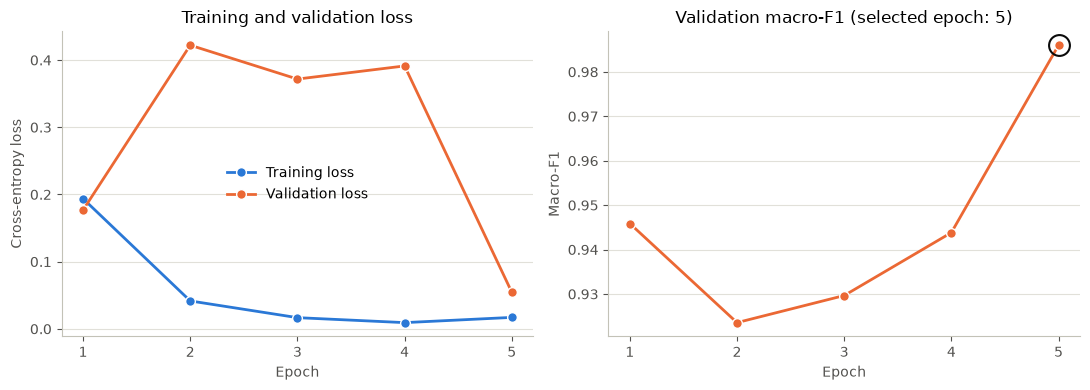

In [13]:
# We plot the training curve. The circled point is the epoch we selected.
history_table = pd.DataFrame(training_history)
curve_figure, (loss_axis, f1_axis) = plt.subplots(1, 2, figsize=(11, 4))
loss_axis.plot(history_table["epoch"], history_table["training_loss"], marker="o", markersize=7,
               markeredgecolor="white", linewidth=2, color=training_color, label="Training loss")
loss_axis.plot(history_table["epoch"], history_table["validation_loss"], marker="o", markersize=7,
               markeredgecolor="white", linewidth=2, color=validation_color, label="Validation loss")
loss_axis.set_title("Training and validation loss")
loss_axis.set_ylabel("Cross-entropy loss")
loss_axis.legend(frameon=False)

best_f1 = history_table.loc[history_table["epoch"] == best_epoch_number, "validation_macro_f1"].iloc[0]
f1_axis.plot(history_table["epoch"], history_table["validation_macro_f1"], marker="o", markersize=7,
             markeredgecolor="white", linewidth=2, color=validation_color)
f1_axis.plot([best_epoch_number], [best_f1], marker="o", markersize=15, markerfacecolor="none",
             markeredgecolor="#0b0b0b", markeredgewidth=1.5, linestyle="none")
f1_axis.set_title(f"Validation macro-F1 (selected epoch: {best_epoch_number})")
f1_axis.set_ylabel("Macro-F1")

for plot_axis in [loss_axis, f1_axis]:
    plot_axis.set_xlabel("Epoch")
    plot_axis.set_xticks(history_table["epoch"])
curve_figure.tight_layout()
curve_figure.savefig(output_directory / "training_curves.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(curve_figure)

## 8. Final test evaluation

We evaluated the fixed majority baseline, selected TF-IDF setting, and selected DistilBERT checkpoint on the same test passages.
We used macro-average F1, accuracy, precision and recall for each class, and confusion matrices.
We defined the human-text false-positive rate as human texts predicted as AI-generated divided by all human test texts.
We did not tune the 0.5 decision threshold on the test set.
We also plotted the test macro-F1 and the human-text false-positive rate of the three models.
We report ROC-AUC as an extra metric that does not depend on the 0.5 threshold.
We estimated a 95% bootstrap confidence interval for the macro-F1 difference between DistilBERT and TF-IDF.

,model,macro_f1,accuracy,human_precision,human_recall,human_f1,ai_generated_precision,ai_generated_recall,ai_generated_f1,human_false_positive_rate,human_support,ai_generated_support
0,Majority baseline,0.3333,0.500,0.5000,1.000,0.6667,0.0000,0.000,0.0000,0.000,250,250
1,TF-IDF logistic regression,0.9380,0.938,0.9328,0.944,0.9384,0.9433,0.932,0.9376,0.056,250,250
2,DistilBERT,0.9800,0.980,0.9724,0.988,0.9802,0.9878,0.972,0.9798,0.012,250,250


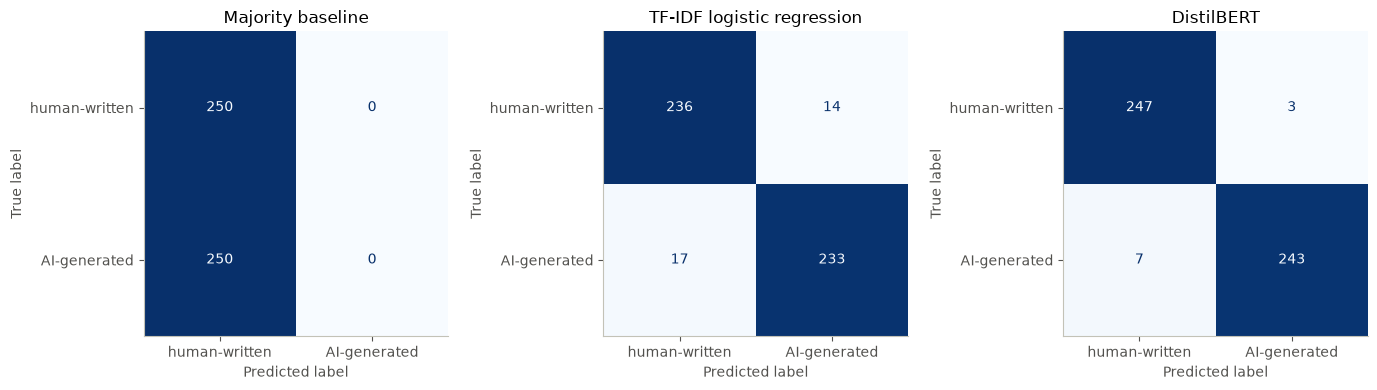

TF-IDF logistic regression test ROC-AUC: 0.9819
DistilBERT test ROC-AUC: 0.9992
DistilBERT minus TF-IDF macro-F1 on the test set: 0.0420
95% bootstrap confidence interval: [0.0201, 0.0642]


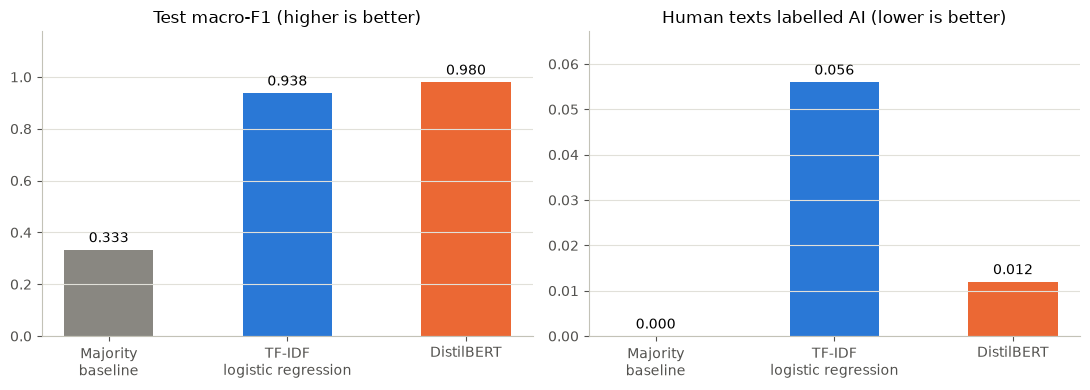

In [14]:
evaluation_start_time = time.perf_counter()
test_loader = make_data_loader(test_answers)
test_predictions = {
    "Majority baseline": np.full(len(test_answers), majority_label),
}
test_ai_generated_probabilities = {
    "TF-IDF logistic regression": selected_baseline.predict_proba(test_answers["passage_text"])[:, 1],
    "DistilBERT": predict_ai_generated_probabilities(distilbert_classifier, test_loader),
}
for model_name, ai_generated_probabilities in test_ai_generated_probabilities.items():
    test_predictions[model_name] = (ai_generated_probabilities >= decision_threshold).astype(int)

test_results = pd.DataFrame([
    {"model": model_name, **calculate_metrics(test_answers["label"], predictions)}
    for model_name, predictions in test_predictions.items()
])
test_results.to_csv(output_directory / "test_metrics.csv", index=False)
display(test_results.round(4))

# We plot one confusion matrix for each model.
confusion_figure, confusion_axes = plt.subplots(1, 3, figsize=(14, 4))
for plot_axis, (model_name, predictions) in zip(confusion_axes, test_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        test_answers["label"], predictions, labels=[0, 1], display_labels=class_names,
        ax=plot_axis, colorbar=False, cmap="Blues",
    )
    plot_axis.set_title(model_name)
    plot_axis.grid(False)
confusion_figure.tight_layout()
confusion_figure.savefig(output_directory / "confusion_matrices.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(confusion_figure)

baseline_test_f1 = test_results.set_index("model").loc["TF-IDF logistic regression", "macro_f1"]
distilbert_test_f1 = test_results.set_index("model").loc["DistilBERT", "macro_f1"]
# ROC-AUC does not depend on the 0.5 threshold, so we report it as an extra metric.
for model_name, ai_generated_probabilities in test_ai_generated_probabilities.items():
    print(model_name, "test ROC-AUC:", round(roc_auc_score(test_answers["label"], ai_generated_probabilities), 4))

# We estimate a 95% confidence interval for the difference by resampling the test answers 2,000 times.
test_labels = test_answers["label"].to_numpy()
bootstrap_generator = np.random.default_rng(SEED)
bootstrap_differences = []
for _ in range(2000):
    sample_indices = bootstrap_generator.integers(0, len(test_labels), len(test_labels))
    distilbert_sample_f1 = f1_score(test_labels[sample_indices], test_predictions["DistilBERT"][sample_indices],
                                    labels=[0, 1], average="macro", zero_division=0)
    baseline_sample_f1 = f1_score(test_labels[sample_indices], test_predictions["TF-IDF logistic regression"][sample_indices],
                                  labels=[0, 1], average="macro", zero_division=0)
    bootstrap_differences.append(distilbert_sample_f1 - baseline_sample_f1)
lower_bound, upper_bound = np.percentile(bootstrap_differences, [2.5, 97.5])
save_json(output_directory / "test_difference.json", {
    "distilbert_minus_tfidf_macro_f1": float(distilbert_test_f1 - baseline_test_f1),
    "bootstrap_95_percent_interval": [float(lower_bound), float(upper_bound)],
})
print(f"DistilBERT minus TF-IDF macro-F1 on the test set: {distilbert_test_f1 - baseline_test_f1:.4f}")
print(f"95% bootstrap confidence interval: [{lower_bound:.4f}, {upper_bound:.4f}]")

# We compare the three models on the two main test metrics.
comparison_figure, comparison_axes = plt.subplots(1, 2, figsize=(11, 4))
model_tick_labels = [model_name.replace(" ", "\n", 1) for model_name in test_results["model"]]
bar_colors = [model_colors[model_name] for model_name in test_results["model"]]
for plot_axis, metric_name, axis_title in zip(
    comparison_axes,
    ["macro_f1", "human_false_positive_rate"],
    ["Test macro-F1 (higher is better)", "Human texts labelled AI (lower is better)"],
):
    bars = plot_axis.bar(model_tick_labels, test_results[metric_name], width=0.5, color=bar_colors)
    plot_axis.bar_label(bars, fmt="%.3f", padding=3)
    plot_axis.set_ylim(0, test_results[metric_name].max() * 1.2)
    plot_axis.set_title(axis_title)
comparison_figure.tight_layout()
comparison_figure.savefig(output_directory / "test_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(comparison_figure)

## 9. Error analysis

We compared test performance by source and passage length to locate errors. These are descriptive checks within HC3, not tests on unseen domains.
We inspected confident false positives and false negatives for both learned models.
We also inspected logistic regression features to identify possible dataset shortcuts.
We did not use this analysis to retune the evaluated models.
We plotted macro-F1 by source, and the human-text false-positive rate for full answers and answers cut at the token limit.
We also trained a length-only logistic regression on the passage token count as a reference for the length shortcut.

,model,grouping,group,answer_count,macro_f1,human_false_positive_rate
0,DistilBERT,source,finance,82,1.0000,0.0000
1,DistilBERT,source,medicine,28,1.0000,0.0000
2,DistilBERT,source,open_qa,20,0.9499,0.0000
3,DistilBERT,source,reddit_eli5,358,0.9804,0.0056
4,DistilBERT,source,wiki_csai,12,0.8286,0.3333
5,Majority baseline,source,finance,82,0.3333,0.0000
6,Majority baseline,source,medicine,28,0.3333,0.0000
7,Majority baseline,source,open_qa,20,0.3333,0.0000
8,Majority baseline,source,reddit_eli5,358,0.3333,0.0000
9,Majority baseline,source,wiki_csai,12,0.3333,0.0000


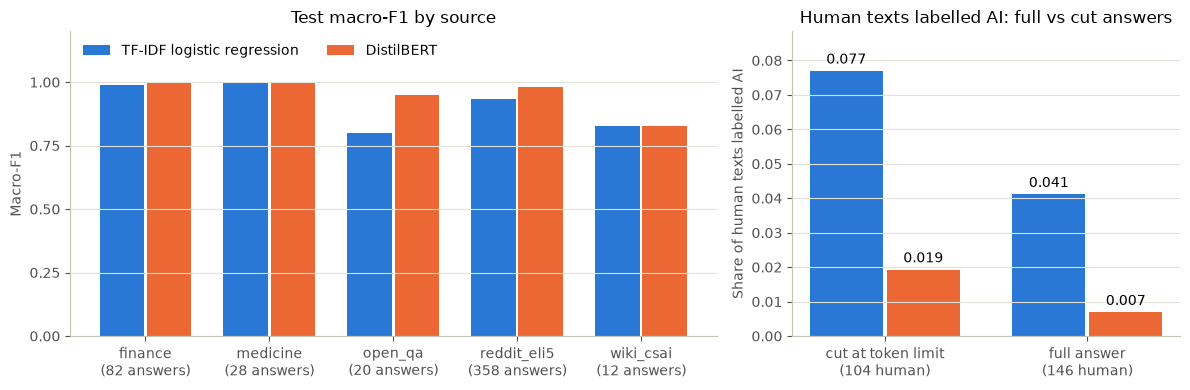

Length-only reference, validation macro-F1: 0.7317
Length-only reference, test macro-F1: 0.7241


,model,error_type,source,ai_generated_probability,passage_text
0,TF-IDF logistic regression,Human text labelled AI,reddit_eli5,0.702600,A hedge fund is an investment fund that uses h...
1,TF-IDF logistic regression,Human text labelled AI,wiki_csai,0.667660,"In mathematics, projective geometry is the stu..."
2,TF-IDF logistic regression,Human text labelled AI,reddit_eli5,0.649643,Dilation can be a sign of being under the effe...
3,TF-IDF logistic regression,Human text labelled AI,reddit_eli5,0.617165,We often used high concentration HF acid to et...
4,TF-IDF logistic regression,Human text labelled AI,finance,0.598629,A company's Return on Equity (ROE) is its net ...
5,TF-IDF logistic regression,AI text labelled human,open_qa,0.242400,Muse is an English rock band formed in Teignmo...
6,TF-IDF logistic regression,AI text labelled human,reddit_eli5,0.290998,"Sure! So, when you're talking about the resolu..."
7,TF-IDF logistic regression,AI text labelled human,reddit_eli5,0.322420,A 30% chance of rain means that there is a 30%...
8,TF-IDF logistic regression,AI text labelled human,reddit_eli5,0.346745,The human brain is really good at finding patt...
9,TF-IDF logistic regression,AI text labelled human,reddit_eli5,0.371009,​ ··· ChatGPT Dec 15 Version. Free Research Pr...


,human_associated_feature,human_coefficient,ai_generated_associated_feature,ai_generated_coefficient
0,url_0,-2.685542,can,3.568446
1,just,-2.615286,or,3.534721
2,but,-2.539275,it is,3.108848
3,my,-2.453400,help,2.611468
4,so,-2.395987,may,2.600979
5,do,-2.382261,important,2.505970
6,etc,-2.374896,such as,2.467869
7,only,-2.152249,important to,2.362679
8,you,-2.060690,might,2.251489
9,what,-1.914394,and,2.186627


In [15]:
prediction_rows = []
for model_name, predictions in test_predictions.items():
    model_predictions = test_answers.copy()
    model_predictions["model"] = model_name
    model_predictions["predicted_label"] = predictions
    model_predictions["ai_generated_probability"] = test_ai_generated_probabilities.get(model_name, np.full(len(test_answers), np.nan))
    prediction_rows.append(model_predictions)
prediction_table = pd.concat(prediction_rows, ignore_index=True)
prediction_table.drop(columns="passage_text").to_csv(output_directory / "test_predictions.csv", index=False)
# We compare full answers with answers cut at the token limit, because most AI answers are cut.
prediction_table["length_group"] = np.where(prediction_table["was_truncated"], "cut at token limit", "full answer")

slice_result_rows = []
for grouping_column in ["source", "length_group"]:
    for (model_name, group_name), group_answers in prediction_table.groupby(["model", grouping_column], observed=True):
        slice_result_rows.append({
            "model": model_name, "grouping": grouping_column, "group": str(group_name),
            "answer_count": len(group_answers),
            **calculate_metrics(group_answers["label"], group_answers["predicted_label"]),
        })
slice_results = pd.DataFrame(slice_result_rows)
slice_results.to_csv(output_directory / "test_slice_metrics.csv", index=False)
display(slice_results[["model", "grouping", "group", "answer_count", "macro_f1", "human_false_positive_rate"]].round(4))

def plot_model_bars_by_group(plot_axis, grouping_column, metric_name, count_column, count_word):
    # We draw one bar for each learned model in each group, and we show the group size under its name.
    grouping_rows = slice_results[slice_results["grouping"] == grouping_column]
    group_names = list(grouping_rows["group"].unique())
    bar_width = 0.38
    model_bars = []
    for model_index, model_name in enumerate(["TF-IDF logistic regression", "DistilBERT"]):
        model_rows = grouping_rows[grouping_rows["model"] == model_name].set_index("group").loc[group_names]
        bar_positions = np.arange(len(group_names)) + (model_index - 0.5) * bar_width
        model_bars.append(plot_axis.bar(bar_positions, model_rows[metric_name], width=bar_width * 0.95,
                                        color=model_colors[model_name], label=model_name))
    group_counts = grouping_rows.drop_duplicates("group").set_index("group").loc[group_names, count_column]
    tick_labels = [f"{group_name}\n({group_count} {count_word})" for group_name, group_count in zip(group_names, group_counts)]
    plot_axis.set_xticks(np.arange(len(group_names)), tick_labels)
    return model_bars


# We plot macro-F1 by source, and the human-text false-positive rate for full and cut answers.
slice_figure, (source_axis, truncation_axis) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [5, 3]})
plot_model_bars_by_group(source_axis, "source", "macro_f1", "answer_count", "answers")
source_axis.set_ylim(0, 1.2)
source_axis.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
source_axis.set_ylabel("Macro-F1")
source_axis.set_title("Test macro-F1 by source")
source_axis.legend(frameon=False, loc="upper left", ncol=2)
truncation_bars = plot_model_bars_by_group(truncation_axis, "length_group", "human_false_positive_rate", "human_support", "human")
# We write the values on these bars, because a rate of zero has no visible bar.
for bars in truncation_bars:
    truncation_axis.bar_label(bars, fmt="%.3f", padding=3)
truncation_axis.margins(y=0.15)
truncation_axis.set_ylabel("Share of human texts labelled AI")
truncation_axis.set_title("Human texts labelled AI: full vs cut answers")
slice_figure.tight_layout()
slice_figure.savefig(output_directory / "test_f1_by_group.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close(slice_figure)

# We check how well answer length alone separates the classes, because length is a possible shortcut.
length_only_classifier = LogisticRegression()
length_only_classifier.fit(training_answers[["content_token_count"]], training_answers["label"])
for split_name, answer_table in [("validation", validation_answers), ("test", test_answers)]:
    length_only_predictions = length_only_classifier.predict(answer_table[["content_token_count"]])
    length_only_f1 = f1_score(answer_table["label"], length_only_predictions, average="macro")
    print(f"Length-only reference, {split_name} macro-F1:", round(length_only_f1, 4))

# We show the five most confident mistakes of each kind for the two learned models.
error_examples = []
for model_name in ["TF-IDF logistic regression", "DistilBERT"]:
    model_rows = prediction_table[prediction_table["model"] == model_name]
    human_errors = model_rows[(model_rows["label"] == 0) & (model_rows["predicted_label"] == 1)]
    human_errors = human_errors.sort_values("ai_generated_probability", ascending=False).head(5)
    error_examples.append(human_errors.assign(error_type="Human text labelled AI"))
    ai_generated_errors = model_rows[(model_rows["label"] == 1) & (model_rows["predicted_label"] == 0)]
    ai_generated_errors = ai_generated_errors.sort_values("ai_generated_probability").head(5)
    error_examples.append(ai_generated_errors.assign(error_type="AI text labelled human"))
error_examples = pd.concat(error_examples, ignore_index=True)
error_examples.to_csv(output_directory / "error_examples.csv", index=False)
display(error_examples[["model", "error_type", "source", "ai_generated_probability", "passage_text"]])

# Negative coefficients point to human-written text and positive coefficients point to AI-generated text.
feature_names = selected_baseline.named_steps["tfidf"].get_feature_names_out()
feature_coefficients = selected_baseline.named_steps["classifier"].coef_[0]
ordered_feature_indices = np.argsort(feature_coefficients)
important_features = pd.DataFrame({
    "human_associated_feature": feature_names[ordered_feature_indices[:10]],
    "human_coefficient": feature_coefficients[ordered_feature_indices[:10]],
    "ai_generated_associated_feature": feature_names[ordered_feature_indices[-10:][::-1]],
    "ai_generated_coefficient": feature_coefficients[ordered_feature_indices[-10:][::-1]],
})
important_features.to_csv(output_directory / "logistic_regression_features.csv", index=False)
display(important_features)

## 10. Saved results and limitations

We saved the settings, split membership, validation results, test results, figures, and the selected TF-IDF pipeline.
We use the saved tables and figures as evidence in the report. We include the selected sample size, frozen layers, device, and measured runtime.
We keep this executed notebook with the report so the reported results can be traced to one run.

We evaluated English answers from early ChatGPT and specific HC3 sources. We did not establish performance on newer generators, essays, edited AI text, or mixed authorship.
We used a balanced sample and one random seed. Other class proportions and random splits can change performance.
We removed exact duplicates, but related questions and shared writing patterns may remain.
We limited answers to their initial passage, which can remove useful evidence.
We treat detector outputs as experimental predictions, not proof of misconduct.

We discuss these limits, dataset terms, possible false accusations, and relevant ACL ARR checklist items in the final report.

In [16]:
evaluation_and_analysis_seconds = time.perf_counter() - evaluation_start_time
total_runtime_seconds = time.perf_counter() - run_start_time
runtime_summary = {
    "download_or_cache_lookup_seconds": download_seconds,
    "baseline_seconds": baseline_seconds,
    "distilbert_training_and_selection_seconds": distilbert_training_seconds,
    "test_evaluation_and_analysis_seconds": evaluation_and_analysis_seconds,
    "total_runtime_seconds": total_runtime_seconds,
    "total_runtime_with_download_seconds": total_runtime_seconds + download_seconds,
    "runtime_limit_seconds": runtime_limit_seconds,
    "within_runtime_limit": total_runtime_seconds <= runtime_limit_seconds,
    "question_count": number_of_questions,
    "selected_distilbert_epoch": best_epoch_number,
    "device": str(computing_device),
}
save_json(output_directory / "runtime_summary.json", runtime_summary)
display(pd.Series(runtime_summary, name="Run summary").to_frame())
print("We saved this run in:", output_directory)
print("Total runtime in minutes:", round(total_runtime_seconds / 60, 1))
# Additional check for runtime limit exceeded
if not runtime_summary["within_runtime_limit"]:
    print("The run took longer than one hour. Please reduce number_of_questions or increase "
          "frozen_transformer_layers, then run all cells again.")

,Run summary
download_or_cache_lookup_seconds,6.492785
baseline_seconds,0.731713
distilbert_training_and_selection_seconds,1767.295802
test_evaluation_and_analysis_seconds,15.242842
total_runtime_seconds,1796.48612
total_runtime_with_download_seconds,1802.978905
runtime_limit_seconds,3600
within_runtime_limit,True
question_count,2500
selected_distilbert_epoch,5


We saved this run in: /home/fcsvmuser/Downloads/outputs/20261121_150944
Total runtime in minutes: 29.9
